# 02 · Los dos alelos de `BUB1B` — curación estilo ACMG

> **Saneado:** sin posición, sin identidad de aminoácidos, sin coordenadas. Los alelos se
> nombran por su papel (`truncante`, `missense`), que es lo que importa para la curación.
>
> **Esto es curación de investigación, no un informe clínico.** El entregable del proyecto es
> una hipótesis falsable, nunca una recomendación.

## Pregunta biológica

**¿Qué sostiene cada alelo por separado, y qué haría falta para que el par sea causal?**

## Hipótesis y preregistro

`docs/DECISIONS.md`. Los umbrales de `PP3` se sellaron **antes** de mirar REVEL, precisamente
para que un predictor no informativo no se sumara a conveniencia.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


## Entradas, QC de las dos llamadas

Antes de curar nada: ¿son buenas las llamadas? Una curación sobre una llamada mala es ruido
con formato ACMG.

In [2]:
from src.paths import patient_vcf
from src.prioritization.genome_wide import load

rows = load("work/gw/highmod_ann.tsv", patient_vcf())
seen, alleles = set(), []
for v in rows:
    if v.gene != "BUB1B" or v.impact not in ("HIGH", "MODERATE"):
        continue
    k = (v.loc, v.allele)
    if k in seen:
        continue
    seen.add(k); alleles.append(v)

ROLE = {"HIGH": "alelo A · truncante", "MODERATE": "alelo B · missense"}
for v in alleles:
    ab = v.allele_balance
    print(f"  {ROLE.get(v.impact, v.impact):<24} GT={v.gt}  DP={v.dp}  GQ={v.gq}  "
          f"AB={ab:.2f}  FILTER={v.filt}  MAX_AF="
          f"{('%.2e' % v.max_af) if v.max_af is not None else 'AUSENTE'}")

  alelo A · truncante      GT=0/1  DP=46  GQ=99  AB=0.54  FILTER=PASS  MAX_AF=9.98e-05
  alelo B · missense       GT=0/1  DP=28  GQ=99  AB=0.46  FILTER=PASS  MAX_AF=AUSENTE


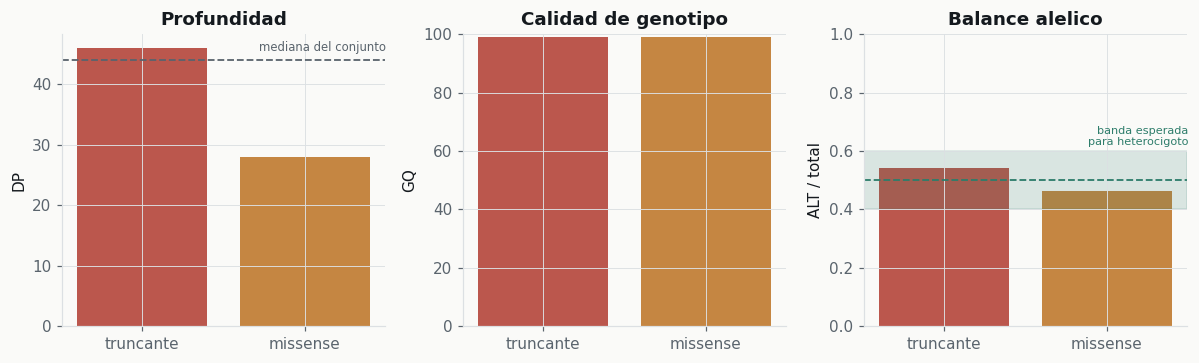

> **Figura QC · las dos llamadas, antes de curar nada**  
> `EXP-007` · **MEASURED**  
> *Qué enseña:* profundidad por encima de la mediana del conjunto, GQ maxima y balance alelico dentro de la banda esperada para heterocigotos en ambos alelos. Las llamadas son solidas.  
> **Qué NO demuestra:** que buenas llamadas impliquen causalidad. El balance alelico sirve para QC y mosaicismo; NO establece que los alelos esten en trans.  
> procedencia: `VCF del paciente, cruzado por identidad de alelo`

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.4))
labels = [ROLE.get(v.impact, v.impact).split("·")[1].strip() for v in alleles]
cols = [fl.DEAD if v.impact == "HIGH" else fl.OPEN for v in alleles]

axes[0].bar(labels, [v.dp for v in alleles], color=cols, alpha=0.9)
axes[0].axhline(44, color=fl.SOFT, ls="--", lw=1.2)
axes[0].text(1.5, 45.5, "mediana del conjunto", fontsize=7.6, color=fl.SOFT, ha="right")
axes[0].set_title("Profundidad"); axes[0].set_ylabel("DP")

axes[1].bar(labels, [v.gq for v in alleles], color=cols, alpha=0.9)
axes[1].set_ylim(0, 100); axes[1].set_title("Calidad de genotipo"); axes[1].set_ylabel("GQ")

abs_ = [v.allele_balance for v in alleles]
axes[2].bar(labels, abs_, color=cols, alpha=0.9)
axes[2].axhspan(0.40, 0.60, color=fl.ALIVE, alpha=0.16)
axes[2].axhline(0.5, color=fl.ALIVE, ls="--", lw=1.2)
axes[2].set_ylim(0, 1); axes[2].set_title("Balance alelico"); axes[2].set_ylabel("ALT / total")
axes[2].text(1.5, 0.62, "banda esperada\npara heterocigoto", fontsize=7.4, color=fl.ALIVE,
             ha="right")

fl.done(fig, "Figura QC · las dos llamadas, antes de curar nada", "EXP-007", "MEASURED",
        "profundidad por encima de la mediana del conjunto, GQ maxima y balance alelico "
        "dentro de la banda esperada para heterocigotos en ambos alelos. Las llamadas son "
        "solidas.",
        "que buenas llamadas impliquen causalidad. El balance alelico sirve para QC y "
        "mosaicismo; NO establece que los alelos esten en trans.",
        prov="VCF del paciente, cruzado por identidad de alelo")

## Resultado primario 1 · el paisaje de missense en ClinVar

`PM1`, `PS1` y `PM5` se evalúan sobre la clase comparable. El error que esto corrigió: contar
«0 P/LP frente a 35 B/LB» mezclaba todas las consecuencias — **31 de esas 35 eran sinónimas**.

In [4]:
d = json.load(io.open("work/clinvar/landscape_missense.json", encoding="utf-8"))
tot = d["totals"]
print("  ClinVar sobre TODO el gen, solo missense:")
for k, v in tot.items():
    print(f"    {k:<14}{v:>6}")
print()
print(f"  -> {100*tot.get('VUS',0)/sum(tot.values()):.0f} % son VUS. Ningun punto del gen")
print("     tiene hotspot demostrable, asi que PM1 no aplica en NINGUNA parte.")

  ClinVar sobre TODO el gen, solo missense:
    P/LP               1
    B/LB              35
    VUS             1426

  -> 98 % son VUS. Ningun punto del gen
     tiene hotspot demostrable, asi que PM1 no aplica en NINGUNA parte.


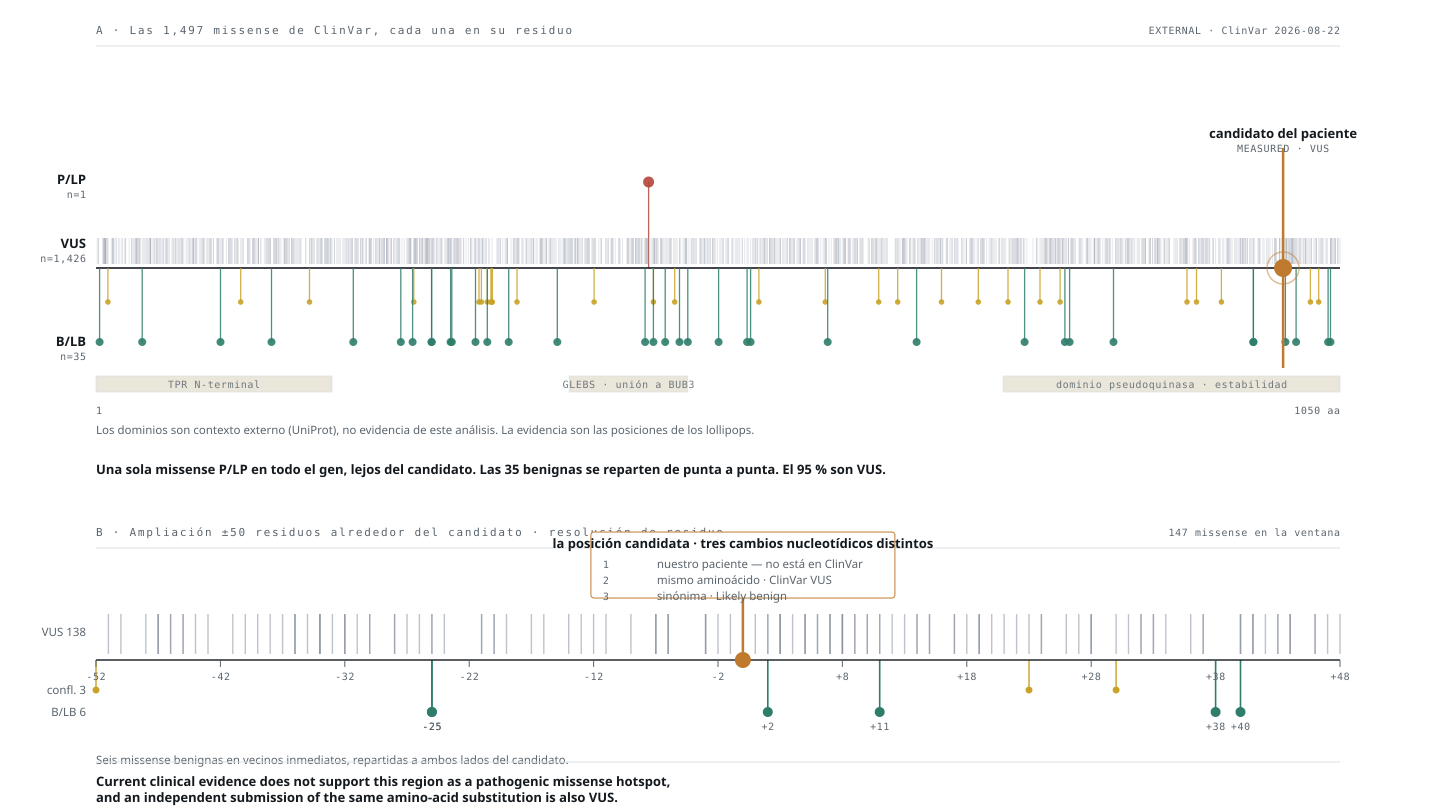

> **Figura principal 1 · las missense de ClinVar en todo el gen**  
> `EXP-007` · **EXTERNAL**  
> *Qué enseña:* cada missense de ClinVar en su residuo, y la ampliacion alrededor del candidato en coordenadas RELATIVAS. Una sola P/LP en todo el gen, 35 benignas repartidas de punta a punta, y 95 % de VUS.  
> **Qué NO demuestra:** que la ausencia de hotspot sea evidencia CONTRA este candidato. PM1 no aplica por ausencia de hotspot en cualquier parte del gen, que es distinto.  
> procedencia: `src/make_fig2b.py → fig2_landscape.svg · sha256[:12]=223ccbdc36c9`

In [5]:
fl.svg("figures/fig2_landscape.svg",
       "Figura principal 1 · las missense de ClinVar en todo el gen",
       "EXP-007", "EXTERNAL",
       "cada missense de ClinVar en su residuo, y la ampliacion alrededor del candidato en "
       "coordenadas RELATIVAS. Una sola P/LP en todo el gen, 35 benignas repartidas de punta "
       "a punta, y 95 % de VUS.",
       "que la ausencia de hotspot sea evidencia CONTRA este candidato. PM1 no aplica por "
       "ausencia de hotspot en cualquier parte del gen, que es distinto.",
       generator="src/make_fig2b.py")

## Resultado primario 2 · geometría de NMD y de la fase

Dos medidas geométricas deciden dos cosas distintas: si el truncante activa NMD, y si los dos
alelos pueden conectarse con lecturas cortas.

In [6]:
g = json.load(io.open("work/struct/fig3_exons.json", encoding="utf-8"))
ptc, last = g["ptc_cds"], g["last_junction"]
margin = last - ptc
print(f"  distancia del PTC a la ultima union exon-exon : {margin:,} nt")
print(f"  umbral de la regla 50-55 nt                   : 50-55 nt")
print(f"  margen                                        : ~{margin/52:.0f}x el umbral")
print()
print("  -> NMD predicho con holgura. PVS1 candidato, con el arbol de decision recorrido.")

  distancia del PTC a la ultima union exon-exon : 748 nt
  umbral de la regla 50-55 nt                   : 50-55 nt
  margen                                        : ~14x el umbral

  -> NMD predicho con holgura. PVS1 candidato, con el arbol de decision recorrido.


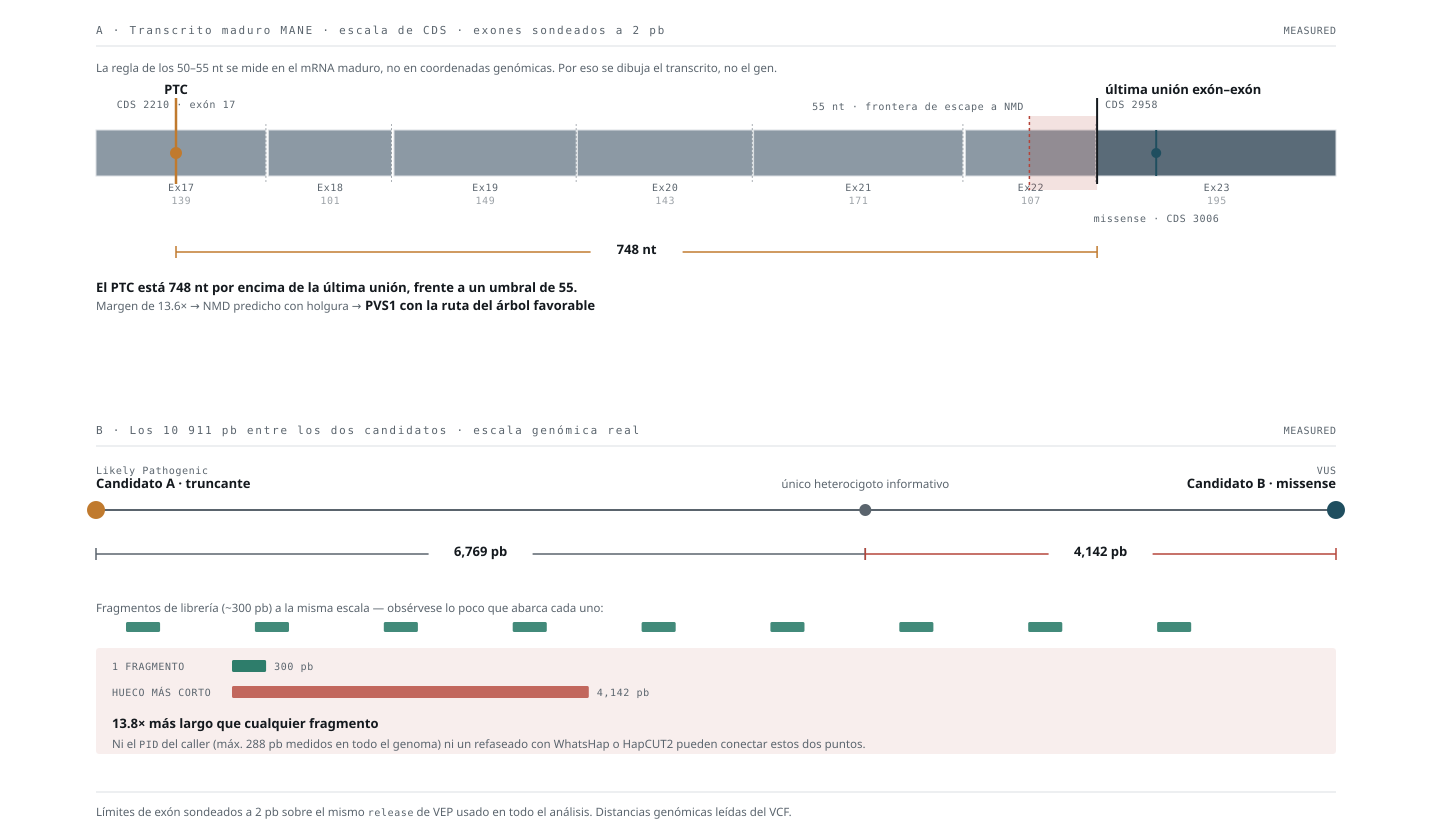

> **Figura principal 2 · geometria de NMD y de la fase**  
> `EXP-007 · EXP-013` · **MEASURED+DERIVED**  
> *Qué enseña:* el PTC cae a ~748 nt de la ultima union exon-exon, muy por encima del umbral de 50-55 nt: NMD predicho con holgura. Y abajo, por que la fase no se resuelve: el hueco entre los dos alelos es de ~11 kb frente a fragmentos de ~300 pb, con un solo heterocigoto intermedio.  
> **Qué NO demuestra:** que los dos alelos esten en trans. `unphased` no es `trans`: el bloque de fase mas largo de todo el genoma mide 288 pb. La fase no resuelta PERMANECE no resuelta.  
> procedencia: `src/make_fig3.py → fig3_phase.svg · sha256[:12]=c20e1536c662`

In [7]:
fl.svg("figures/fig3_phase.svg",
       "Figura principal 2 · geometria de NMD y de la fase",
       "EXP-007 · EXP-013", "MEASURED+DERIVED",
       f"el PTC cae a ~{margin:,} nt de la ultima union exon-exon, muy por encima del umbral "
       "de 50-55 nt: NMD predicho con holgura. Y abajo, por que la fase no se resuelve: el "
       "hueco entre los dos alelos es de ~11 kb frente a fragmentos de ~300 pb, con un solo "
       "heterocigoto intermedio.",
       "que los dos alelos esten en trans. `unphased` no es `trans`: el bloque de fase mas "
       "largo de todo el genoma mide 288 pb. La fase no resuelta PERMANECE no resuelta.",
       generator="src/make_fig3.py")

## Robustez · el techo de cada alelo, y qué lo movería

La curación no termina en una etiqueta: termina sabiendo **cuánta evidencia falta y de qué
tipo**.

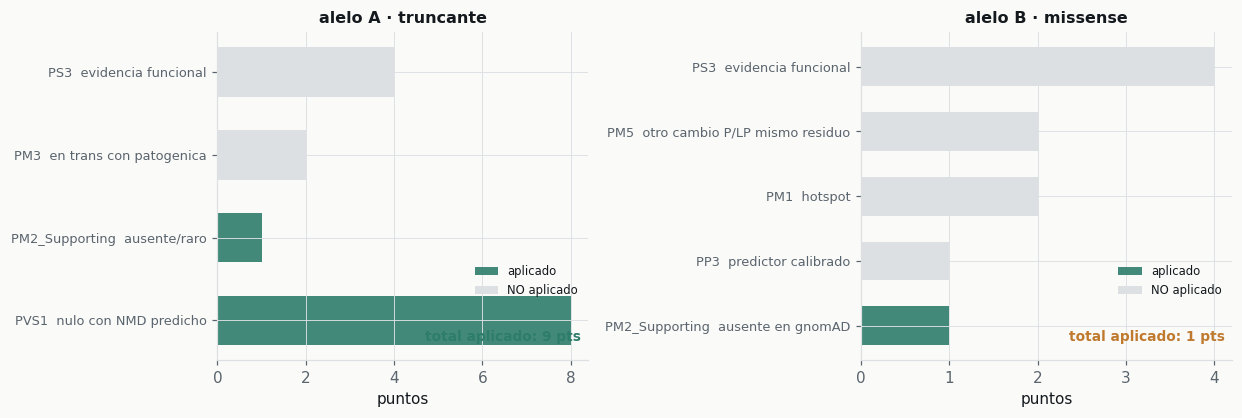

> **Figura de robustez · puntos ACMG aplicados y los que faltan**  
> `EXP-007` · **DERIVED**  
> *Qué enseña:* el truncante suma 9 puntos (PVS1 + PM2_Supporting) y llega a Likely Pathogenic. El missense suma 1: se queda en VUS, y seguiria en VUS aunque entrara PP3, porque el maximo alcanzable con PM1+PM5 son 5 puntos y VUS llega hasta 5.  
> **Qué NO demuestra:** que los puntos no aplicados sean evidencia en contra. PM3 esta bloqueado por DECISION, mas conservador que ClinGen; PP3 no aplica porque REVEL dio 0,472, por debajo del umbral SELLADO ANTES de mirarlo.  
> procedencia: `docs/ACMG_CURATION.md · umbrales preregistrados en DECISIONS.md`

In [8]:
# Puntos del marco bayesiano de ClinGen, tal y como se aplicaron
EVID = {
 "alelo A · truncante": [("PVS1  nulo con NMD predicho", 8, True),
                          ("PM2_Supporting  ausente/raro", 1, True),
                          ("PM3  en trans con patogenica", 2, False),
                          ("PS3  evidencia funcional", 4, False)],
 "alelo B · missense": [("PM2_Supporting  ausente en gnomAD", 1, True),
                         ("PP3  predictor calibrado", 1, False),
                         ("PM1  hotspot", 2, False),
                         ("PM5  otro cambio P/LP mismo residuo", 2, False),
                         ("PS3  evidencia funcional", 4, False)],
}
fig, axes = plt.subplots(1, 2, figsize=(11.4, 3.9))
for ax, (name, items) in zip(axes, EVID.items()):
    ys = range(len(items))
    got = [p if ok else 0 for _, p, ok in items]
    miss = [0 if ok else p for _, p, ok in items]
    ax.barh(list(ys), got, color=fl.ALIVE, alpha=0.9, height=0.6, label="aplicado")
    ax.barh(list(ys), miss, color=fl.RULE, height=0.6, label="NO aplicado")
    ax.set_yticks(list(ys)); ax.set_yticklabels([t for t, _, _ in items], fontsize=8.4)
    ax.set_xlabel("puntos"); ax.set_title(name, fontsize=10.5)
    ax.axvline(0, color=fl.INK, lw=1)
    total = sum(got)
    ax.text(0.98, 0.06, f"total aplicado: {total} pts", transform=ax.transAxes,
            ha="right", fontsize=9, fontweight="bold",
            color=fl.ALIVE if total >= 6 else fl.OPEN)
    ax.legend(fontsize=7.6, frameon=False, loc="lower right", bbox_to_anchor=(1, 0.16))

fl.done(fig, "Figura de robustez · puntos ACMG aplicados y los que faltan",
        "EXP-007", "DERIVED",
        "el truncante suma 9 puntos (PVS1 + PM2_Supporting) y llega a Likely Pathogenic. El "
        "missense suma 1: se queda en VUS, y seguiria en VUS aunque entrara PP3, porque el "
        "maximo alcanzable con PM1+PM5 son 5 puntos y VUS llega hasta 5.",
        "que los puntos no aplicados sean evidencia en contra. PM3 esta bloqueado por "
        "DECISION, mas conservador que ClinGen; PP3 no aplica porque REVEL dio 0,472, por "
        "debajo del umbral SELLADO ANTES de mirarlo.",
        prov="docs/ACMG_CURATION.md · umbrales preregistrados en DECISIONS.md")

## Evidencia contradictoria, declarada

**SIFT `deleterious` 0,01 y PolyPhen 0,997 apuntaban fuerte a patogenicidad.** El predictor
calibrado dice que no hay evidencia asignable. Sumar los dos primeros habría dado un `PP3`
injustificado — **se ve el tamaño del error que el preregistro evitó**.

Y un error propio: afirmé que ninguna candidata estaba en dbSNP, deduciéndolo de la columna
`ID` vacía del VCF. **Falso**: esa columna solo indica que el caller no anotó. El truncante sí
está, y en ClinVar como patogénico.

## Decisión

| | |
|---|---|
| **Alelo A · truncante** | **Likely Pathogenic** (9 pts) |
| **Alelo B · missense** | **VUS**, y sigue VUS aunque entrara `PP3` |
| **El par** | *one likely pathogenic truncating allele + one rare missense candidate, **phase unresolved*** |

### Qué NO establece

**No es heterocigosis compuesta demostrada.** `PM3` sigue bloqueado, la fase sigue sin
resolver, y sin eso el modelo bialélico es *candidato*, no establecido.

### Falsificador

Genotipos parentales, o lectura larga dirigida sobre los ~11 kb que separan los dos alelos.
Cualquiera de los dos convierte «candidato» en resuelto — **en la dirección que sea**.

### Siguiente experimento

`03_BUBR1_MECHANISM` — si el missense no se mueve por clasificación, ¿se mueve por mecanismo?